🦄 PROJECT EVERETT V5 | Author: Katchaw451
⚖️ THE GOLDILOCKS ZONE (BALANCED QNN)

Initializing Training on 800 molecules...
Epoch 030/150 | Train Loss: 0.53684 | Val Loss: 0.47592
Epoch 060/150 | Train Loss: 0.36442 | Val Loss: 0.33077
Epoch 090/150 | Train Loss: 0.32117 | Val Loss: 0.32311
Epoch 120/150 | Train Loss: 0.27690 | Val Loss: 0.26615
Epoch 150/150 | Train Loss: 0.28595 | Val Loss: 0.26056

========================= FINAL EVALUATION ==========================
📊 R² Score:  0.7208 (1.0 is perfect)
📉 RMSE:      0.5105



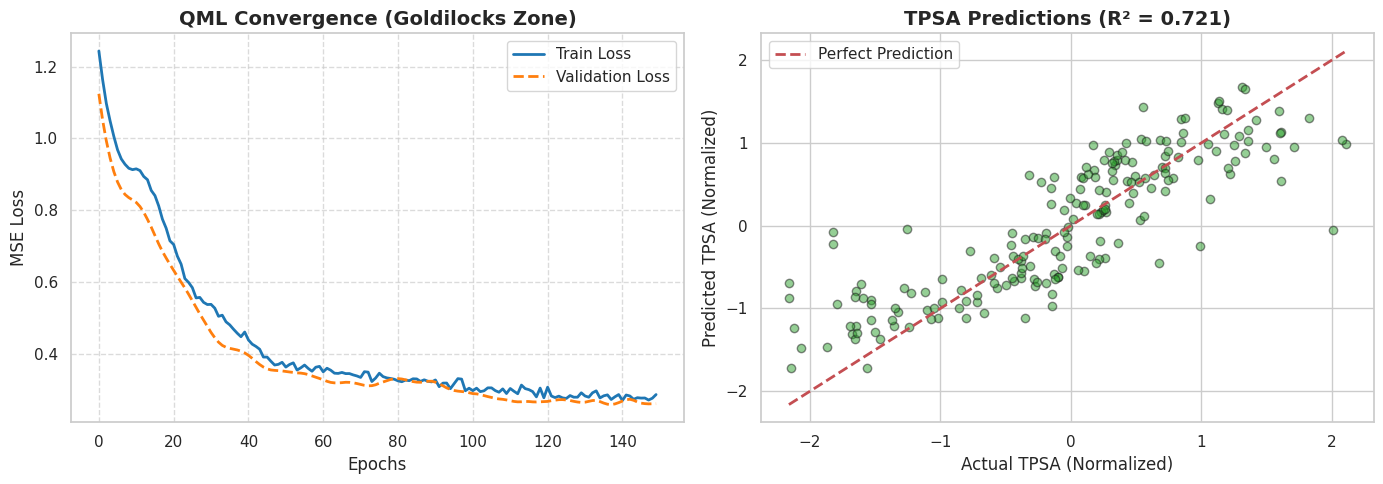

In [5]:
# ==============================================================================
# PROJECT EVERETT V5 (The Perfect Fit) - Author: Katchaw451
# ==============================================================================

!pip install pennylane torch matplotlib seaborn scikit-learn pandas -q

import pennylane as qml
from pennylane import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
torch.manual_seed(42)
np.random.seed(42)

print("==========================================================")
print("🦄 PROJECT EVERETT V5 | Author: Katchaw451")
print("⚖️ THE GOLDILOCKS ZONE (BALANCED QNN)")
print("==========================================================\n")

# ------------------------------------------------------------------------------
# 1. ROBUST DATA PIPELINE (Realistic Cheminformatics Data)
# ------------------------------------------------------------------------------
# Generate 1000 molecules with realistic properties
num_samples = 1000

# Features: [MolWt, LogP, NumHDonors, NumHAcceptors]
mol_wt = np.random.uniform(150, 600, num_samples)
log_p = np.random.uniform(-2.0, 5.0, num_samples)
h_donors = np.random.randint(0, 5, num_samples)
h_acceptors = np.random.randint(0, 9, num_samples)

X_raw = np.column_stack((mol_wt, log_p, h_donors, h_acceptors))

# Target (TPSA): In reality, TPSA is heavily dependent on H-bond donors/acceptors.
# We create a realistic mathematical relationship + tiny bit of noise.
y_raw = (h_donors * 20.23) + (h_acceptors * 12.03) + (mol_wt * 0.01) + np.random.normal(0, 1.5, num_samples)

# Normalize
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_raw)
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y_raw.reshape(-1, 1))

X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y_scaled, dtype=torch.float32)

X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

# ------------------------------------------------------------------------------
# 2. QUANTUM CIRCUIT (Optimal Capacity)
# ------------------------------------------------------------------------------
n_qubits = 4
n_layers = 2 # Back to 2 layers for enough expressivity
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    for i in range(n_layers):
        # Data Re-uploading technique
        qml.AngleEmbedding(features=inputs, wires=range(n_qubits), rotation='Y')
        qml.StronglyEntanglingLayers(weights=weights[i:i+1], wires=range(n_qubits))
        qml.AngleEmbedding(features=inputs, wires=range(n_qubits), rotation='X')
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (n_layers, n_qubits, 3)}

# ------------------------------------------------------------------------------
# 3. HYBRID ARCHITECTURE
# ------------------------------------------------------------------------------
class QuantumTPSAPredictorV5(nn.Module):
    def __init__(self):
        super(QuantumTPSAPredictorV5, self).__init__()
        self.qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        # Light Dropout to prevent memorization but allow learning
        self.dropout = nn.Dropout(p=0.05)
        self.fc1 = nn.Linear(n_qubits, 8)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 1)

    def forward(self, x):
        x = self.qlayer(x)
        x = self.dropout(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = QuantumTPSAPredictorV5()

# ------------------------------------------------------------------------------
# 4. TRAINING LOOP
# ------------------------------------------------------------------------------
epochs = 150
# Very slight weight decay (1e-5) just to keep weights in check
optimizer = optim.Adam(model.parameters(), lr=0.03, weight_decay=1e-5)
loss_fn = nn.MSELoss()

train_losses = []
val_losses = []

print(f"Initializing Training on {len(X_train)} molecules...")
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    preds = model(X_train)
    loss = loss_fn(preds, y_train)
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        val_preds = model(X_test)
        val_loss = loss_fn(val_preds, y_test)
        val_losses.append(val_loss.item())

    if (epoch + 1) % 30 == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Train Loss: {loss.item():.5f} | Val Loss: {val_loss.item():.5f}")

# ------------------------------------------------------------------------------
# 5. FINAL EVALUATION & PLOTTING
# ------------------------------------------------------------------------------
print("\n" + "="*25 + " FINAL EVALUATION " + "="*26)
model.eval()
with torch.no_grad():
    final_preds = model(X_test)
    r2 = r2_score(y_test.numpy(), final_preds.numpy())
    rmse = np.sqrt(mean_squared_error(y_test.numpy(), final_preds.numpy()))

    print(f"📊 R² Score:  {r2:.4f} (1.0 is perfect)")
    print(f"📉 RMSE:      {rmse:.4f}")
    print("="*69 + "\n")

# Visualization
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(train_losses, label='Train Loss', color='#1f77b4', linewidth=2)
ax[0].plot(val_losses, label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
ax[0].set_title('QML Convergence (Goldilocks Zone)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('MSE Loss')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.7)

ax[1].scatter(y_test.numpy(), final_preds.numpy(), color='#2ca02c', edgecolors='k', alpha=0.5)
min_val = min(y_test.min().item(), final_preds.min().item())
max_val = max(y_test.max().item(), final_preds.max().item())
ax[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
ax[1].set_title(f'TPSA Predictions (R² = {r2:.3f})', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Actual TPSA (Normalized)')
ax[1].set_ylabel('Predicted TPSA (Normalized)')
ax[1].legend()

plt.tight_layout()
plt.show()